# Transfer learning under distribution shifts and heterogeneous feature spaces

This notebook accompanies the simulation study in Section 5 of the paper. We compare source-pretrained and target-only FT-MDN-Transformer (FT-MDN-T) models on the same target observations. The design varies the distribution shift, the predictors available in each domain and the number of labeled target recoveries.

Select a mode in the first code cell, then choose **Run All**.

| Mode | Execution |
|---|---|
| `review` (default) | Uses the saved simulation runs, rescores 60 sets of density forecasts and regenerates the tables and figures. |
| `rebuild` | Generates synthetic data and fits or resumes the experiments in `outputs/simulation_rebuild`. The validation study takes the longest to run. |

Run the notebook from the repository root or the notebooks directory. The reference runs used Python 3.9.19 on CPU with one Torch thread. [Dependencies](../requirements.txt) · [Generator configuration](../configs/simulation/source_data_config_categories.yaml)

### Figures and tables

| Paper item | Notebook section | Output |
|---|---|---|
| Figure 11 · Transfer gains across shifts and schemas | 1 | `paired_gain_r2.pdf` |
| Figure 12 · Sensitivity to target training duration | 2 | `training_sensitivity.pdf` |
| Figure 13 · Point and density forecasts at three target sizes | 3 | `three_budget_forecasts.pdf` |
| Online appendix, Figure 1 · Synthetic source and target domains | 1 | `generator_diagnostics.pdf` |
| Online appendix, Figures 2–3 · Absolute performance and feature-augmented ridge | 4 | `absolute_r2.pdf`, `augmentation_r2.pdf` |
| Online appendix, Table 1 · Point and density scores | 3 | Scores by model and target size |
| Online appendix, Figure 4 · Validation results across target sample sizes | 5 | `transfer_vs_target_size_reconstruction.pdf` |

The manuscript figure filenames carry the prefix `revision_`. The [repository guide](../README.md#where-to-find-each-paper-result) also lists the empirical figures.

## Setup

In [3]:
MODE = "review"  # review | rebuild
from itertools import product
from pathlib import Path
import os, sys, subprocess
import pandas as pd
import torch
import warnings
# Pandas 1.4 announces a future LaTeX API change once for each table export.
warnings.filterwarnings("ignore", message=r"In future versions .*DataFrame.to_latex.*",
                        category=FutureWarning, module=r"simulation\.(paper_results|augmentation)")
from IPython.display import display, FileLink
root = Path.cwd().resolve()
repo = root if (root / "src/simulation").is_dir() else root.parent
if MODE not in {"review","rebuild"} or not (repo/"src/simulation").is_dir():
    raise ValueError("Select a documented mode and start in Code Repository or notebooks.")
sys.path.insert(0,str(repo/"src"))
from simulation.notebook_reporting import quiet_epochs, rebuild_panel, show_figure
from simulation.paper_results import export
from simulation.figure_inventory import plot_generator, plot_historical, plot_augmentation
from simulation.augmentation import augmentation_panel
from simulation import density_confirmation as dc
torch.set_num_threads(1)
config = repo/"configs/simulation/source_data_config_categories.yaml"
outputs = repo/"outputs"
if MODE == "rebuild":
    outputs = outputs/"simulation_rebuild"
paper = outputs/"simulation_paper"
primary, longer = outputs/"simulation_revision_v1", outputs/"simulation_sensitivity_80"
final, historical = paper/"final", paper/"historical"
raw_root = outputs/"historical_replay"
print(f"Mode {MODE} | Python {sys.version.split()[0]} | Torch {torch.__version__} | output {outputs.relative_to(repo)}")
from simulation.table_reporting import present_table


Mode review | Python 3.9.19 | Torch 2.6.0 | output outputs


## 1. Transfer gains across shifts and feature schemas

Five paired replications per condition, with a 20-epoch target cap.

In [5]:
if MODE == "rebuild":
    rebuild_panel(config, primary, 20)
table = export(config, primary, final)
plot_generator(config, final)

### Synthetic source and target domains · Online appendix Figure 1

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/final/generator_diagnostics.pdf

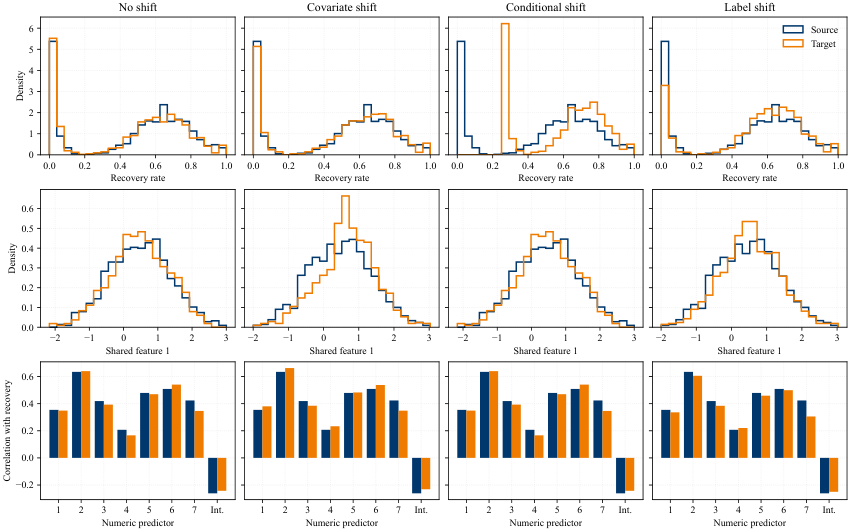

In [7]:
show_figure(final/"generator_diagnostics.pdf")

### Transfer gains · Figure 11

,gain_r2,gain_mae
budget,,
100,0.581,0.09269
500,0.2432,0.04628


/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/final/paired_gain_r2.pdf

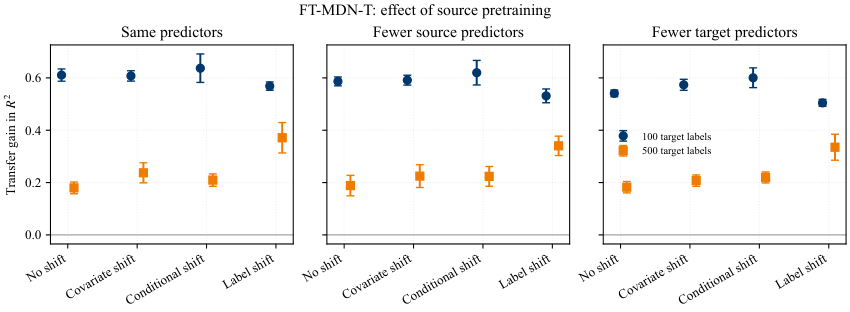

In [9]:
present_table(table.groupby("budget")[["gain_r2","gain_mae"]].mean())
show_figure(final/"paired_gain_r2.pdf")

## 2. Sensitivity to target training duration

Repeat the matched no-shift and label-shift settings with an 80-epoch target cap.

In [12]:
if MODE == "rebuild":
    rebuild_panel(config, longer, 80)
table = export(config, primary, final, sensitivity=longer)

### Training sensitivity · Figure 12

,mean,MCSE
gain_r2_80,0.3133,0.02687
gain_mae_80,0.05152,0.005877


,gain_r2_20,gain_r2_80,gain_mae_80
budget,,,
100,0.5562,0.3332,0.05664
500,0.2671,0.01985,0.005121


,both_improved_80,scratch_at_cap_80
budget,,
100,20,8
500,15,4


/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/final/training_sensitivity.pdf

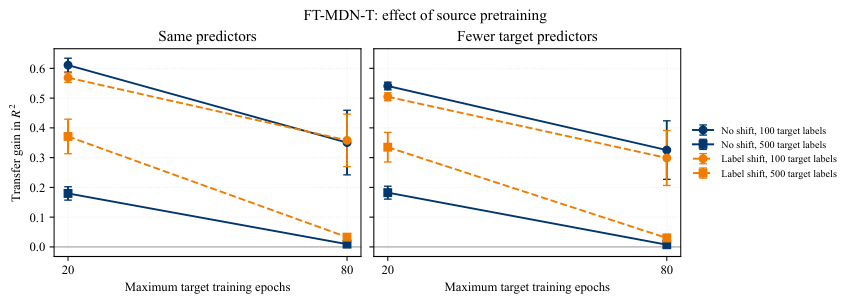

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/final/sensitivity.csv

In [14]:
pairs = pd.read_csv(final / "sensitivity_pairs.csv")
metrics = ["gain_r2_80", "gain_mae_80"]
by_seed = pairs.groupby(["rep", "budget"])[metrics].mean()
contrast = by_seed.xs(100, level="budget") - by_seed.xs(500, level="budget")
present_table(pd.DataFrame({"mean": contrast.mean(), "MCSE": contrast.sem()}))

pairs["both_improved_80"] = (pairs.gain_r2_80>0) & (pairs.gain_mae_80>0)
present_table(pairs.groupby("budget")[["gain_r2_20","gain_r2_80","gain_mae_80"]].mean())
present_table(pairs.groupby("budget")[["both_improved_80","scratch_at_cap_80"]].sum())
show_figure(final/"training_sensitivity.pdf")
present_table(FileLink(os.path.relpath(final/"sensitivity.csv")))

## 3. Point and density forecasts at three target sizes

Five new replications at 100, 250 and 500 target labels, with up to 160 target epochs. The 250-label extension was added after examining the endpoints.

In [16]:
import hashlib
density_root = outputs/"simulation_density_confirmation"
if MODE == "rebuild":
    with quiet_epochs():
        confirmation = dc.run(config,density_root)
else:
    confirmation = density_root/"cd51b94bd7c3"
protocol = confirmation/"protocol.json"
if not protocol.is_file() or hashlib.sha256(protocol.read_bytes()).hexdigest()[:12] != confirmation.name:
    raise ValueError(f"Missing or inconsistent density protocol: {protocol}. Restore the archive or use rebuild.")
expected = {f"{r}-{s}-{h}-{b}.npz" for r,s,h,b in product(dc.REPS,dc.SCHEMAS,dc.SHIFTS,dc.BUDGETS)}
available = {p.name for p in confirmation.glob("*.npz")}
if available != expected:
    raise ValueError(f"Density archive mismatch. Missing: {sorted(expected-available)}. Unexpected: {sorted(available-expected)}.")
print(f"Density assessment | {len(expected)} paired cases | protocol {confirmation.name}")
with quiet_epochs():
    learning_curve = dc.midpoint(config, confirmation, outputs/"simulation_density_midpoint",
                                 fit=MODE=="rebuild")
if learning_curve is None:
    raise FileNotFoundError("Restore the archived 250-label forecasts or select rebuild.")

mid_root = outputs/"simulation_density_midpoint"
mid_run = (dc._folder(config, mid_root, (250,)) if MODE == "rebuild"
           else mid_root/"7103cc9b0f9a")
scores = pd.concat([pd.read_csv(folder/"absolute_scores.csv") for folder in (confirmation,mid_run)])
absolute = scores.groupby(["budget","arm"])[["R2","MAE","CRPS","NLL","coverage80","width80"]].mean()

Density assessment | 40 paired cases | protocol cd51b94bd7c3


### Point and density scores · Online appendix Table 1

In [18]:
print("Mean assessment scores for each model")
present_table(absolute)
print("Paired gain from pretraining and MCSE across five replication averages")
present_table(learning_curve)

Mean assessment scores for each model


Paired gain from pretraining and MCSE across five replication averages


### Target sample size · Figure 13

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/final/three_budget_forecasts.pdf

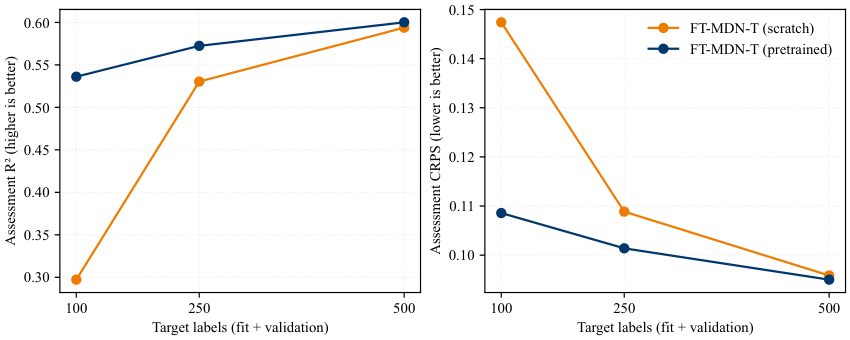

In [20]:
from simulation.paper_results import PAPER_STYLE, BLUE, ORANGE
import matplotlib.pyplot as plt
with plt.rc_context(PAPER_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), constrained_layout=True)
    for ax, metric in zip(axes, ("R2", "CRPS")):
        for arm, color, label in (("scratch", ORANGE, "FT-MDN-T (scratch)"), ("transfer", BLUE, "FT-MDN-T (pretrained)")):
            series = absolute.xs(arm, level="arm")[metric]
            ax.plot(series.index, series.values, marker="o", color=color, label=label)
        ax.set(xlabel="Target labels (fit + validation)", xticks=[100, 250, 500],
               ylabel="Assessment R² (higher is better)" if metric=="R2" else "Assessment CRPS (lower is better)")
    axes[1].legend()
    fig.savefig(final/"three_budget_forecasts.pdf", metadata={"CreationDate":None})
    plt.close(fig)
show_figure(final/"three_budget_forecasts.pdf")

### Paired gains and checkpoint diagnostics

In [22]:
present_table(dc.summarize(confirmation))
ft_scores = scores.loc[scores.arm != "ridge"].copy()
ft_scores["ran_to_cap"] = ft_scores.epochs_run.eq(dc.CAP)
ft_scores["selected_cap"] = ft_scores.selected_epoch.eq(dc.CAP)
present_table(ft_scores.groupby(["budget","arm"])[["ran_to_cap","selected_cap"]].sum())
present_table(FileLink(os.path.relpath(mid_run/"three_budget_by_rep.csv")))
present_table(FileLink(os.path.relpath(confirmation/"scarcity_contrast_by_rep.csv")))

,mean,MCSE
CRPS,0.03798,0.01084
R2,0.2326,0.0465
MAE,0.03747,0.006475
NLL,0.3432,0.1032


/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_density_midpoint/7103cc9b0f9a/three_budget_by_rep.csv

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_density_confirmation/cd51b94bd7c3/scarcity_contrast_by_rep.csv

## 4. Model comparisons across feature schemas

Compare the main 20-epoch runs with target-only and residual XGBoost, and feature-augmented ridge.

In [24]:
if MODE == "rebuild":
    augmentation_panel(config, primary, final)
keys = ["shift", "schema", "budget", "rep"]
runs = pd.read_csv(final / "replications.csv").merge(
    pd.read_csv(final / "augmentation_runs.csv"), on=keys, validate="one_to_one")
assert len(runs) == 120
runs["FT_minus_augmented_ridge_R2"] = runs.transfer_r2 - runs.augmented_r2
present_table(runs.groupby(["schema", "budget"]).FT_minus_augmented_ridge_R2.mean().unstack())
means = runs.groupby(["shift","schema","budget"]).mean(numeric_only=True).reset_index()
means["FT_above_both_trees"] = means.transfer_r2 > means[["xgb_scratch_r2","xgb_residual_r2"]].max(axis=1)
means["FT_above_augmented_ridge"] = means.transfer_r2 > means.augmented_r2
present_table(means.groupby("budget")[["FT_above_both_trees","FT_above_augmented_ridge"]].sum())
present_table(means.query('schema=="equal" and budget==500 and shift in ["none","label"]')
        [["shift","scratch_r2","transfer_r2","gain_r2"]])
print("Primary pairs improving on both metrics:", ((runs.gain_r2>0) & (runs.gain_mae>0)).sum(), "/", len(runs))
plot_augmentation(final)

,100,500
schema,,
equal,-0.04646,-0.03689
source_subset,-0.04466,-0.04445
target_subset,0.01618,0.003293


,FT-MDN-T_above_both_trees,FT-MDN-T_above_augmented_ridge
budget,,
100,10,3
500,6,2


,shift,scratch_r2,transfer_r2,gain_r2
13,label,0.2316,0.6027,0.3712
19,none,0.4609,0.6406,0.1797


Primary pairs improving on both metrics: 120 / 120


### Absolute performance · Online appendix Figure 2

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/final/absolute_r2.pdf

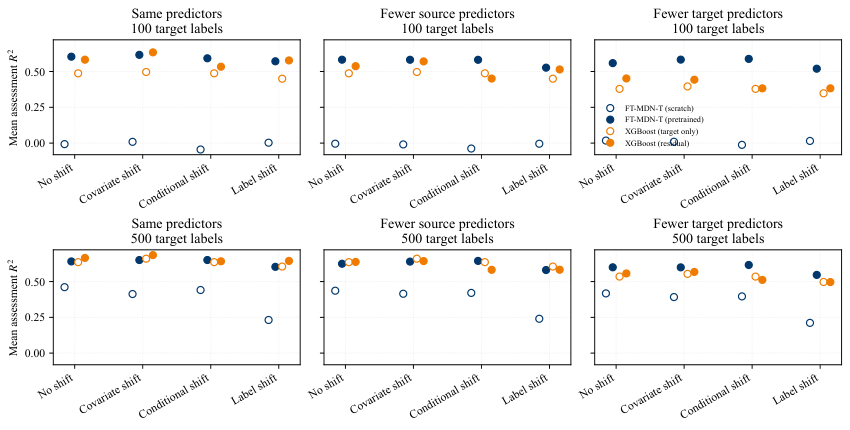

In [26]:
show_figure(final/"absolute_r2.pdf")

### Feature-augmented ridge · Online appendix Figure 3

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/final/augmentation_r2.pdf

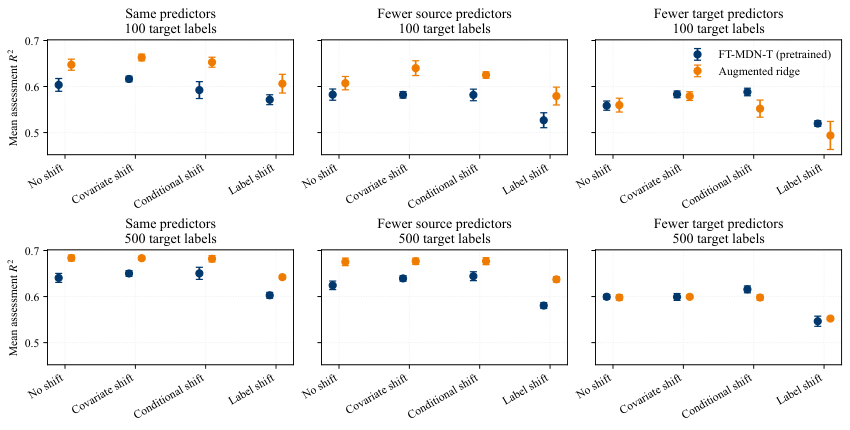

In [31]:
show_figure(final/"augmentation_r2.pdf")

## 5. Validation results across target sample sizes

This analysis covers five target sample sizes from 100 to 1,000 labels. Scores are available for 222 of 225 planned replication settings. These are validation results. Section 3 reports performance on independent assessment observations.

`review` draws the appendix figures from saved runs. `rebuild` executes the [simulation sweep](supporting/simulation_final.ipynb) and writes training output to a log. FT-MDN-T denotes the mixture-density model and FT-Reg the regression-head ablation.

In [33]:
from importlib import reload
from simulation import figure_inventory

if MODE == "rebuild":
    raw_root.mkdir(parents=True,exist_ok=True)
    log = raw_root/"replay_console.log"
    print(f"Validation sweep | 225 planned settings | detailed progress: {log}", flush=True)
    env = dict(os.environ, PYTHONHASHSEED="0", MPLBACKEND="Agg", PYTHONPATH=str(repo/"src"))
    with log.open("a") as stream:
        result = subprocess.run([sys.executable,"-m","simulation.historical_replay",str(repo),str(raw_root)],
                                cwd=repo,env=env,stdout=stream,stderr=subprocess.STDOUT)
    if result.returncode:
        raise RuntimeError(f"Validation sweep exited with {result.returncode}. Inspect {log}")
legacy = reload(figure_inventory).plot_historical(repo,raw_root,historical)
index = pd.read_csv(raw_root/"results/index.csv")
raw = pd.concat([pd.read_csv(raw_root/r.raw).assign(shift=r.shift_type,schema=r.hetero,budget=r.target_n)
                 for r in index.itertuples()],ignore_index=True)
observed = set(raw[["shift","schema","budget","simulation_id"]].itertuples(index=False,name=None))
expected = set(product(("covariate","conditional","label"),("equal","target_subset","source_subset"),
                       (100,250,500,750,1000),range(5)))
print(f"Validation sweep | {len(observed & expected)}/{len(expected)} planned settings present | {len(raw)} model rows")
print("Missing settings:", sorted(expected-observed))
models_per_setting = raw.groupby(["shift","schema","budget","simulation_id"]).model_name.nunique()
print("Settings with all four models:", models_per_setting.eq(4).sum())
ft = raw.loc[raw.model_name=="FT-MDN"].copy()
ft["validation_R2_gain"] = ft.r2_transfer_learning - ft.r2_target_only
present_table(ft.groupby("budget").validation_R2_gain.agg(["count","mean"]))

Validation sweep | 222/225 planned settings present | 888 model rows
Missing settings: [('conditional', 'equal', 250, 0), ('conditional', 'equal', 250, 1), ('conditional', 'equal', 1000, 0)]
Settings with all four models: 222


,count,mean
budget,,
100,45,0.4465
250,43,0.1466
500,45,0.04124
750,45,0.02545
1000,44,0.009512


### Validation learning curve · Online appendix Figure 4

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/historical/transfer_vs_target_size_reconstruction.pdf

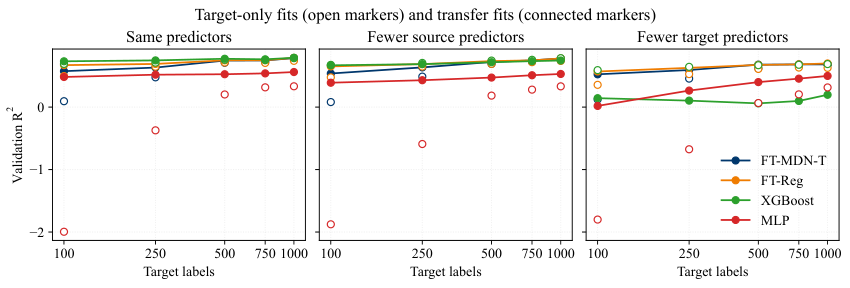

In [35]:
show_figure(historical/"transfer_vs_target_size_reconstruction.pdf")

## 6. Supplementary figures and result files

All panels below use the results calculated in Sections 1–5.

### MAE gains across shifts and schemas

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/final/paired_gain_mae.pdf

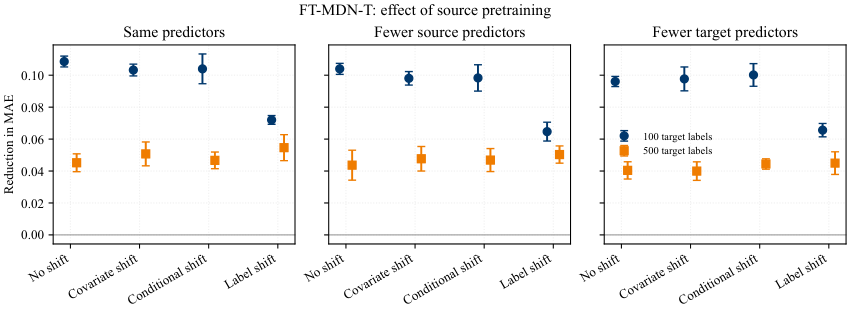

In [38]:
show_figure(final/"paired_gain_mae.pdf")

### Paired replication results

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/final/paired_replications.pdf

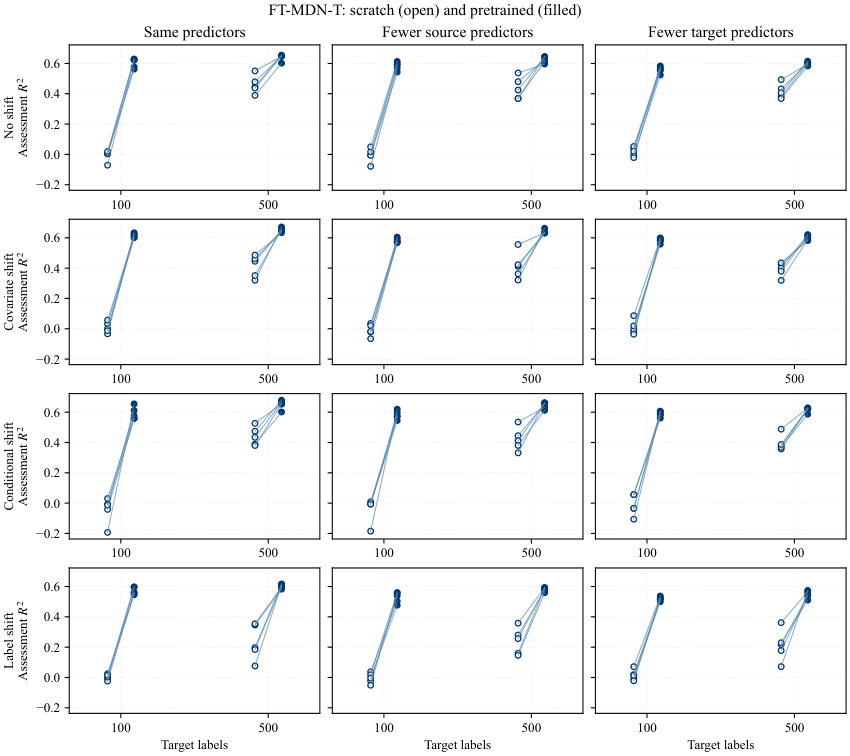

In [42]:
show_figure(final/"paired_replications.pdf")

### Transfer performance by condition

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/final/transfer_heatmap.pdf

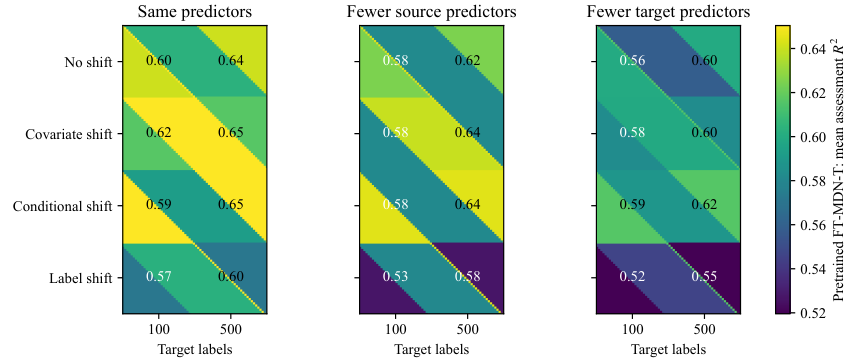

In [44]:
show_figure(final/"transfer_heatmap.pdf")

### Sample-size comparisons within each shift

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/final/sample_size_none.pdf

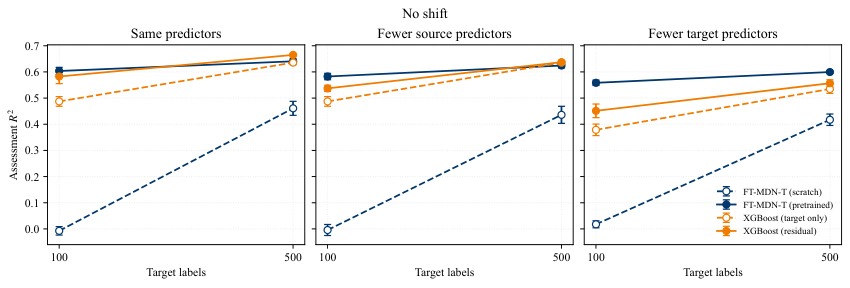

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/final/sample_size_covariate.pdf

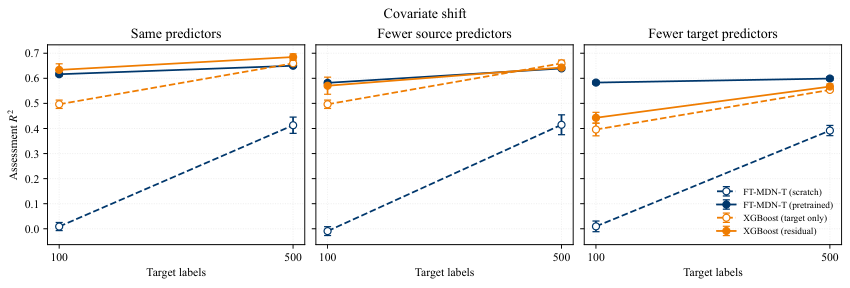

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/final/sample_size_conditional.pdf

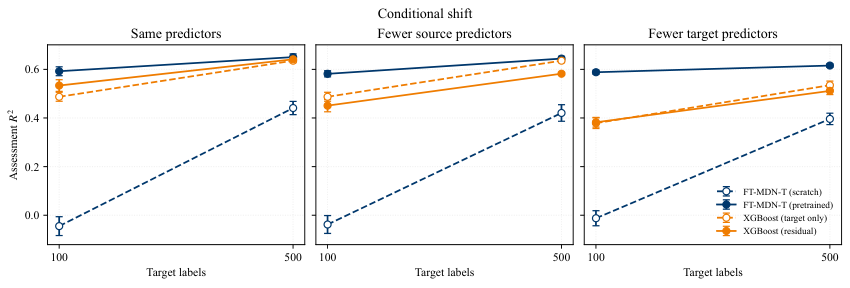

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/final/sample_size_label.pdf

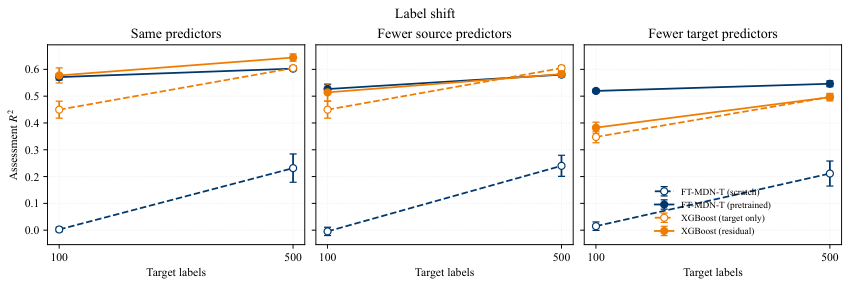

In [46]:
for shift in ("none", "covariate", "conditional", "label"):
    show_figure(final/f"sample_size_{shift}.pdf")

### Validation performance and distributional distance

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/historical/r2_transfer_vs_combinedKL_allTargets.pdf

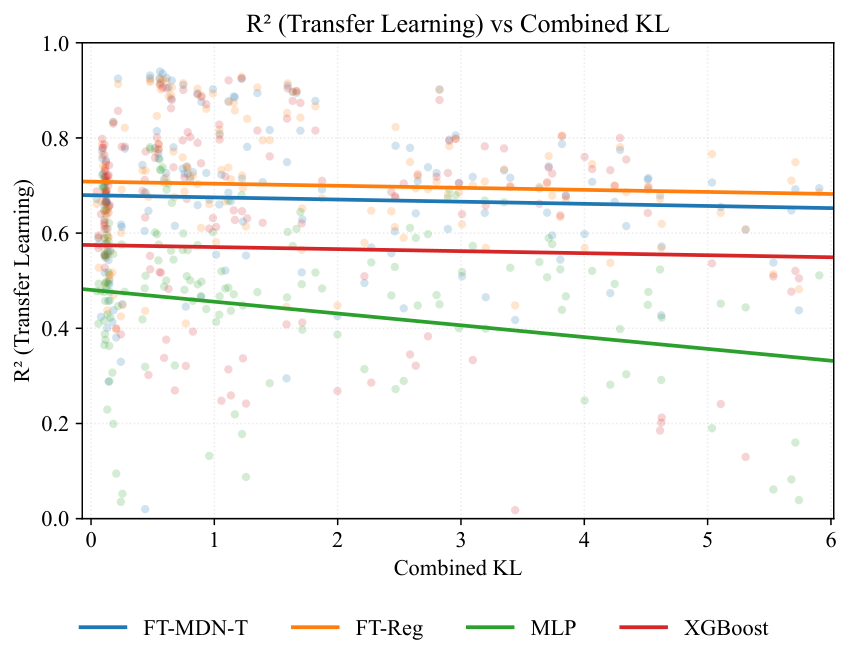

In [51]:
show_figure(historical/"r2_transfer_vs_combinedKL_allTargets.pdf")

### Validation performance by shift and target size

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/historical/r2_transfer_by_shift_target100.pdf

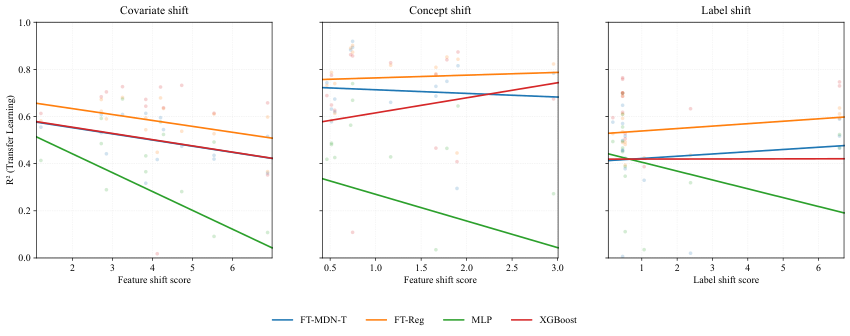

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/historical/r2_transfer_by_shift_target500.pdf

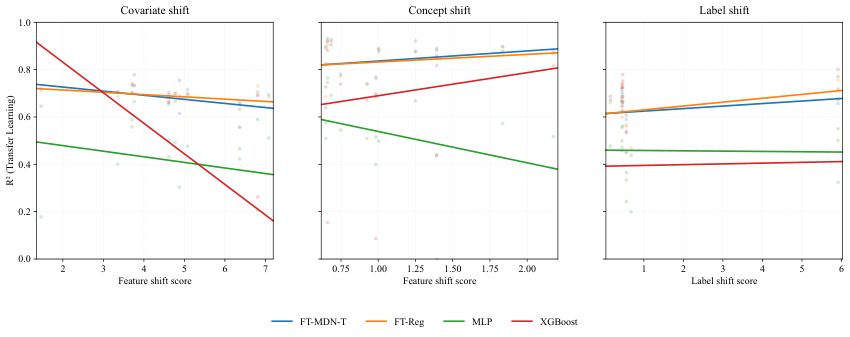

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/historical/r2_transfer_by_shift_target1000.pdf

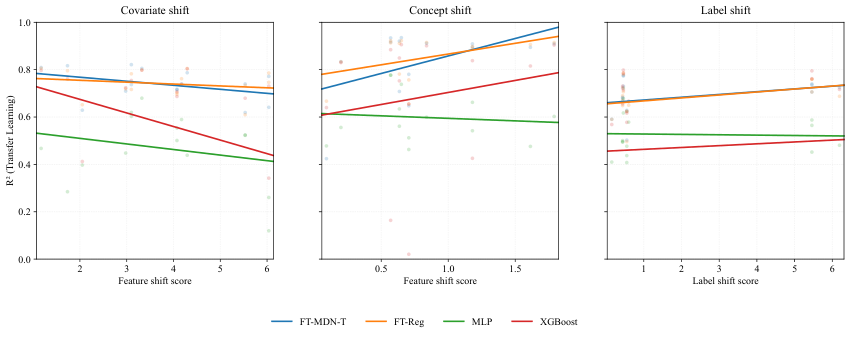

In [54]:
for budget in (100, 500, 1000):
    show_figure(historical/f"r2_transfer_by_shift_target{budget}.pdf")

### Validation performance across schemas

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/historical/hetero_transfer_violin_highlight.pdf

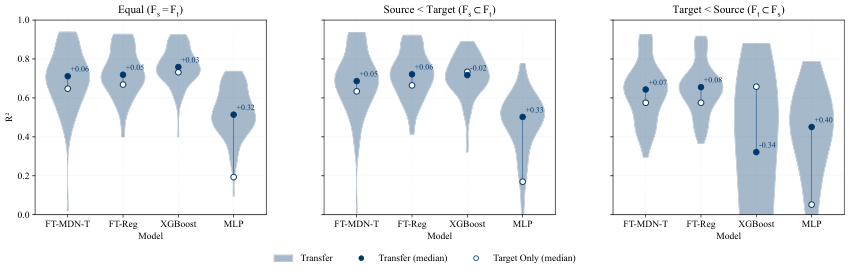

In [59]:
show_figure(historical/"hetero_transfer_violin_highlight.pdf")

### Validation performance heatmap

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/historical/FTMDN_heatmap_headers.pdf

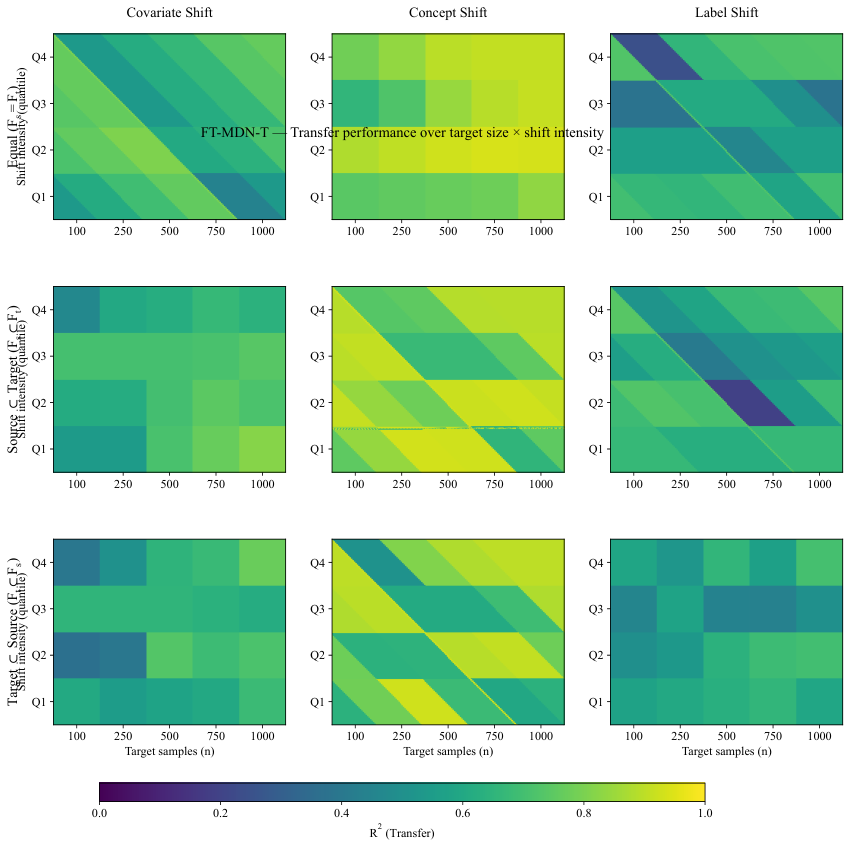

In [61]:
show_figure(historical/"FTMDN_heatmap_headers.pdf")

### Result tables and run manifest

In [73]:
for name in ("condition_means.csv","replications.csv","sensitivity_pairs.csv","augmentation_summary.csv","manifest.json"):
    present_table(FileLink(os.path.relpath(final/name)))
present_table(FileLink(os.path.relpath(historical/"historical_condition_summary.csv")))

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/final/condition_means.csv

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/final/replications.csv

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/final/sensitivity_pairs.csv

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/final/augmentation_summary.csv

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/final/manifest.json

/Users/christophergerling/Documents/Revision TL Paper/Code Repository/outputs/simulation_paper/historical/historical_condition_summary.csv